In [1]:
import sys, os, json, warnings
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import mlflow
import mlflow.pytorch
from sklearn.metrics import roc_auc_score, average_precision_score, PrecisionRecallDisplay

print('PyTorch version:', torch.__version__)
print('GPU available:  ', torch.cuda.is_available())

PyTorch version: 2.12.0+cpu
GPU available:   False


In [2]:
%load_ext autoreload
%autoreload 2


In [3]:
mlflow.set_tracking_uri('http://127.0.0.1:5000')
mlflow.set_experiment('03_Deep_Learning')

CHECKPOINTS = 'artifacts/checkpoints'
VAE_DIR     = 'data/processed/dl_models/vae'
BILSTM_DIR  = 'data/processed/dl_models/bilstm'
TREE_DIR    = 'data/processed/tree_models'

In [4]:
# ── Load processed data ───────────────────────────────────────────────────────
print('Loading VAE data…')
X_vae_train = np.load(f'{VAE_DIR}/X_train.npy')
X_vae_val   = np.load(f'{VAE_DIR}/X_val.npy')
y_train     = np.load(f'{VAE_DIR}/y_train.npy')
y_val       = np.load(f'{VAE_DIR}/y_val.npy')

print(f'VAE train: {X_vae_train.shape}  Val: {X_vae_val.shape}')
print(f'Fraud rate train: {y_train.mean():.3%}  val: {y_val.mean():.3%}')

Loading VAE data…
VAE train: (337352, 88)  Val: (107821, 88)
Fraud rate train: 3.383%  val: 3.913%


In [5]:
# ── Run 3a: Train VAE and evaluate anomaly score ──────────────────────────────
from src.models.vae.train import train_vae, VAE_TRAIN_CFG

print('Training VAE (train on legit only)…')
with mlflow.start_run(run_name='3a_vae_anomaly_score') as run:
    mlflow.log_params(VAE_TRAIN_CFG)
    mlflow.log_params({'model_type': 'VAE', 'train_on': 'legit_only',
                       'input_dim': X_vae_train.shape[1]})

    vae_results = train_vae(
        X_vae_train, y_train, X_vae_val, y_val,
        save_dir=CHECKPOINTS
    )

    mlflow.log_metrics({
        'val_auc_roc': vae_results['val_auc_roc'],
        'val_auc_pr':  vae_results['val_auc_pr'],
    })
    mlflow.pytorch.log_model(vae_results['model'], 'vae_model')

    print(f'VAE AUC-ROC: {vae_results["val_auc_roc"]:.5f}')
    print(f'VAE AUC-PR:  {vae_results["val_auc_pr"]:.5f}')

vae_train_scores = vae_results['train_scores']
vae_val_scores   = vae_results['val_scores']

Training VAE (train on legit only)…


2026-06-14 20:54:24.816 | INFO     | src.models.vae.train:train_vae:67 - VAE training: input_dim=88, latent_dim=16, device=cpu, legit train samples=325941 / 337352 total
2026-06-14 20:54:25.159 | INFO     | src.models.vae.train:train_vae:85 - Saved VAE scaler to artifacts\checkpoints\vae_scaler.pkl
2026-06-14 20:54:32.929 | INFO     | src.models.vae.train:train_vae:159 - Epoch   1/50 — train_loss: 1.03178  val_loss: 75900912836.92308
2026-06-14 20:54:37.483 | INFO     | src.models.vae.train:train_vae:159 - Epoch   2/50 — train_loss: 0.79230  val_loss: 74880897063.38461
2026-06-14 20:54:42.311 | INFO     | src.models.vae.train:train_vae:159 - Epoch   3/50 — train_loss: 0.74573  val_loss: 75450255753.84616
2026-06-14 20:54:46.691 | INFO     | src.models.vae.train:train_vae:159 - Epoch   4/50 — train_loss: 0.71384  val_loss: 75433208674.46153
2026-06-14 20:54:51.421 | INFO     | src.models.vae.train:train_vae:159 - Epoch   5/50 — train_loss: 0.68846  val_loss: 75105380194.46153
2026-06-14

VAE AUC-ROC: 0.55330
VAE AUC-PR:  0.05490
🏃 View run 3a_vae_anomaly_score at: http://127.0.0.1:5000/#/experiments/3/runs/dc661f5c2dbc4eddb4e8314e5d6d7b3c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


In [6]:
# ── Run 3b: Tree model WITH vae_anomaly_score ─────────────────────────────────
import lightgbm as lgb

tree_train = pd.read_parquet(f'{TREE_DIR}/train.parquet')
tree_val   = pd.read_parquet(f'{TREE_DIR}/val.parquet')
tree_train['vae_anomaly_score'] = vae_train_scores
tree_val['vae_anomaly_score']   = vae_val_scores

EXCLUDE = ['TransactionID', 'isFraud', 'uid1', 'uid2', 'uid3', 'uid_magic',
           'card4', 'card6', 'ProductCD', 'DeviceType', 'P_emaildomain',
           'R_emaildomain', 'DeviceInfo', 'device_os', 'device_browser',
           'P_email_tld', 'R_email_tld']

feat_cols = [c for c in tree_train.columns
             if c not in EXCLUDE and tree_train[c].dtype != object]

LGBM_PARAMS = {
    'n_estimators': 3000, 'num_leaves': 512, 'learning_rate': 0.01,
    'subsample': 0.8, 'colsample_bytree': 0.5, 'min_child_samples': 50,
    'scale_pos_weight': 27, 'objective': 'binary',
    'random_state': 42, 'verbose': -1, 'n_jobs': -1,
}

with mlflow.start_run(run_name='3b_lgbm_with_vae_score') as run:
    mlflow.log_params(LGBM_PARAMS)
    mlflow.log_params({'vae_score_included': True, 'n_features': len(feat_cols)})

    model = lgb.LGBMClassifier(**LGBM_PARAMS)
    model.fit(
        tree_train[feat_cols].values, tree_train['isFraud'].values,
        eval_set=[(tree_val[feat_cols].values, tree_val['isFraud'].values)],
        callbacks=[lgb.early_stopping(200, verbose=False), lgb.log_evaluation(500)]
    )

    lgbm_val_preds = model.predict_proba(tree_val[feat_cols].values)[:, 1]
    lgbm_auc  = roc_auc_score(tree_val['isFraud'], lgbm_val_preds)
    lgbm_aupr = average_precision_score(tree_val['isFraud'], lgbm_val_preds)

    mlflow.log_metrics({'val_auc_roc': lgbm_auc, 'val_auc_pr': lgbm_aupr})
    print(f'LGBM+VAE AUC-ROC: {lgbm_auc:.5f}  AUC-PR: {lgbm_aupr:.5f}')

[500]	valid_0's binary_logloss: 0.091662
LGBM+VAE AUC-ROC: 0.93179  AUC-PR: 0.65816
🏃 View run 3b_lgbm_with_vae_score at: http://127.0.0.1:5000/#/experiments/3/runs/9134bfcf70134d5c9e21ac8d9f9cf072
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


In [7]:
# ── Run 3c: BiLSTM ────────────────────────────────────────────────────────────
from src.models.bilstm.train import train_bilstm, BILSTM_TRAIN_CFG

bl_train = pd.read_parquet(f'{BILSTM_DIR}/train.parquet')
bl_val   = pd.read_parquet(f'{BILSTM_DIR}/val.parquet')

print('Training BiLSTM (20-step sequences, 12 features)…')
with mlflow.start_run(run_name='3c_bilstm') as run:
    mlflow.log_params(BILSTM_TRAIN_CFG)
    mlflow.log_params({'model_type': 'BiLSTM', 'seq_len': 20, 'n_step_features': 12})

    bl_results = train_bilstm(bl_train, bl_val, save_dir=CHECKPOINTS)

    mlflow.log_metrics({
        'val_auc_roc': bl_results['val_auc_roc'],
        'val_auc_pr':  bl_results['val_auc_pr'],
    })
    mlflow.pytorch.log_model(bl_results['model'], 'bilstm_model')

    print(f'BiLSTM AUC-ROC: {bl_results["val_auc_roc"]:.5f}  AUC-PR: {bl_results["val_auc_pr"]:.5f}')

bilstm_val_probs = bl_results['val_probs']

2026-06-14 21:00:34.529 | INFO     | src.models.bilstm.train:train_bilstm:56 - BiLSTM training on device: cpu
2026-06-14 21:00:34.530 | INFO     | src.models.bilstm.train:train_bilstm:59 - Building training sequences…
2026-06-14 21:00:34.530 | WARNING  | src.models.bilstm.dataset:build_sequences:65 - BiLSTM missing features (will be zeroed): ['ProductCD_encoded']


Training BiLSTM (20-step sequences, 12 features)…


2026-06-14 21:00:35.000 | INFO     | src.models.bilstm.dataset:build_sequences:88 - Building BiLSTM sequences: N=337352, seq_len=20, features=12…
2026-06-14 21:00:37.267 | INFO     | src.models.bilstm.dataset:build_sequences:115 - BiLSTM sequences built: shape=(337352, 20, 12)
2026-06-14 21:00:37.285 | INFO     | src.models.bilstm.train:train_bilstm:61 - Building validation sequences…
2026-06-14 21:00:37.286 | WARNING  | src.models.bilstm.dataset:build_sequences:65 - BiLSTM missing features (will be zeroed): ['ProductCD_encoded']
2026-06-14 21:00:37.338 | INFO     | src.models.bilstm.dataset:build_sequences:88 - Building BiLSTM sequences: N=107821, seq_len=20, features=12…
2026-06-14 21:00:38.000 | INFO     | src.models.bilstm.dataset:build_sequences:115 - BiLSTM sequences built: shape=(107821, 20, 12)
2026-06-14 21:00:38.409 | DEBUG    | src.preprocessing.sort_and_split:expanding_window_folds:142 - Fold 0: train rows=137321 (day ≤31)  val rows=38409 (day 31–44)
2026-06-14 21:00:38.416

🏃 View run 3c_bilstm at: http://127.0.0.1:5000/#/experiments/3/runs/5e859b152f51454f92ff3d7ac90136a2
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


KeyError: 'model'

In [15]:
print(f'BiLSTM AUC-ROC: {bl_results["val_auc_roc"]:.5f}  AUC-PR: {bl_results["val_auc_pr"]:.5f}')


BiLSTM AUC-ROC: 0.71752  AUC-PR: 0.09495


In [16]:
bilstm_val_probs = bl_results['val_probs']


In [7]:
# ── Run 3d: GNN ───────────────────────────────────────────────────────────────
from src.models.gnn.train import train_gnn, GNN_TRAIN_CFG
import pandas as pd
bl_train = pd.read_parquet(f'{BILSTM_DIR}/train.parquet')
bl_val   = pd.read_parquet(f'{BILSTM_DIR}/val.parquet')

print('Training GNN (5 node types, H-GAT)…')
with mlflow.start_run(run_name='3d_gnn_hgat') as run:
    mlflow.log_params(GNN_TRAIN_CFG)
    mlflow.log_params({'model_type': 'H-GAT', 'node_types': 5,
                       'n_heads': 4, 'n_layers': 2})

    gnn_results = train_gnn(bl_train, bl_val, save_dir=CHECKPOINTS)

    mlflow.log_metrics({
        'val_auc_roc': gnn_results['val_auc_roc'],
        'val_auc_pr':  gnn_results['val_auc_pr'],
    })

    print(f'GNN AUC-ROC: {gnn_results["val_auc_roc"]:.5f}  AUC-PR: {gnn_results["val_auc_pr"]:.5f}')

gnn_val_probs  = gnn_results['val_probs']
ring_risk_vals = gnn_results['ring_risk_score']

2026-06-22 23:06:17.601 | INFO     | src.models.gnn.train:train_gnn:69 - GNN training on device: cpu
2026-06-22 23:06:17.607 | DEBUG    | src.preprocessing.sort_and_split:expanding_window_folds:142 - Fold 0: train rows=137321 (day ≤31)  val rows=38409 (day 31–44)
2026-06-22 23:06:17.609 | DEBUG    | src.preprocessing.sort_and_split:expanding_window_folds:142 - Fold 1: train rows=175730 (day ≤44)  val rows=36719 (day 44–57)
2026-06-22 23:06:17.611 | DEBUG    | src.preprocessing.sort_and_split:expanding_window_folds:142 - Fold 2: train rows=212449 (day ≤57)  val rows=41053 (day 57–69)
2026-06-22 23:06:17.613 | DEBUG    | src.preprocessing.sort_and_split:expanding_window_folds:142 - Fold 3: train rows=253502 (day ≤69)  val rows=37757 (day 69–82)
2026-06-22 23:06:17.615 | DEBUG    | src.preprocessing.sort_and_split:expanding_window_folds:142 - Fold 4: train rows=291259 (day ≤82)  val rows=46093 (day 82–95)
2026-06-22 23:06:17.616 | INFO     | src.preprocessing.sort_and_split:expanding_wind

Training GNN (5 node types, H-GAT)…


2026-06-22 23:06:17.823 | DEBUG    | src.models.gnn.graph_builder:_safe_get:72 - GNN node feats missing (zeroed): ['ProductCD_encoded']
2026-06-22 23:06:19.947 | DEBUG    | src.models.gnn.graph_builder:_safe_get:72 - GNN node feats missing (zeroed): ['ProductCD_encoded']
2026-06-22 23:06:19.957 | INFO     | src.models.gnn.graph_builder:build_graph_data:198 - Graph built: 175730 txn nodes, 9407 card nodes, 269 addr nodes, 60 email nodes, 1151 device nodes.
2026-06-22 23:06:29.519 | INFO     | src.models.gnn.train:train_gnn:169 - Epoch   1/30 — loss: 0.98331  val AUC-ROC: 0.50985  AUC-PR: 0.03863
2026-06-22 23:06:34.952 | INFO     | src.models.gnn.train:train_gnn:169 - Epoch   2/30 — loss: 0.97200  val AUC-ROC: 0.51447  AUC-PR: 0.03846
2026-06-22 23:06:40.455 | INFO     | src.models.gnn.train:train_gnn:169 - Epoch   3/30 — loss: 0.96524  val AUC-ROC: 0.51447  AUC-PR: 0.03866
2026-06-22 23:06:45.281 | INFO     | src.models.gnn.train:train_gnn:169 - Epoch   4/30 — loss: 0.96396  val AUC-RO

GNN AUC-ROC: 0.61557  AUC-PR: 0.05719
🏃 View run 3d_gnn_hgat at: http://127.0.0.1:5000/#/experiments/3/runs/9d6dead9ec7540d78bf38ac2a007c4dc
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


In [ ]:
# ── Run 3e: Early stacking (simple average) ───────────────────────────────────
n_val = len(y_val)
combined = (
    0.4 * lgbm_val_preds[:n_val] +
    0.2 * vae_val_scores[:n_val] +
    0.2 * bilstm_val_probs[:n_val] +
    0.2 * gnn_val_probs[:n_val]
)
combined_auc  = roc_auc_score(y_val, combined)
combined_aupr = average_precision_score(y_val, combined)

with mlflow.start_run(run_name='3e_early_stack_avg') as run:
    mlflow.log_params({'method': 'weighted_average', 'w_lgbm': 0.4,
                       'w_vae': 0.2, 'w_bilstm': 0.2, 'w_gnn': 0.2})
    mlflow.log_metrics({'val_auc_roc': combined_auc, 'val_auc_pr': combined_aupr})

print(f'Simple stack AUC-ROC: {combined_auc:.5f}  AUC-PR: {combined_aupr:.5f}')

🏃 View run 3e_early_stack_avg at: http://127.0.0.1:5000/#/experiments/3/runs/458e21905dfd4a24b6275a63d24b8e3d
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3
Simple stack AUC-ROC: 0.91662  AUC-PR: 0.57324


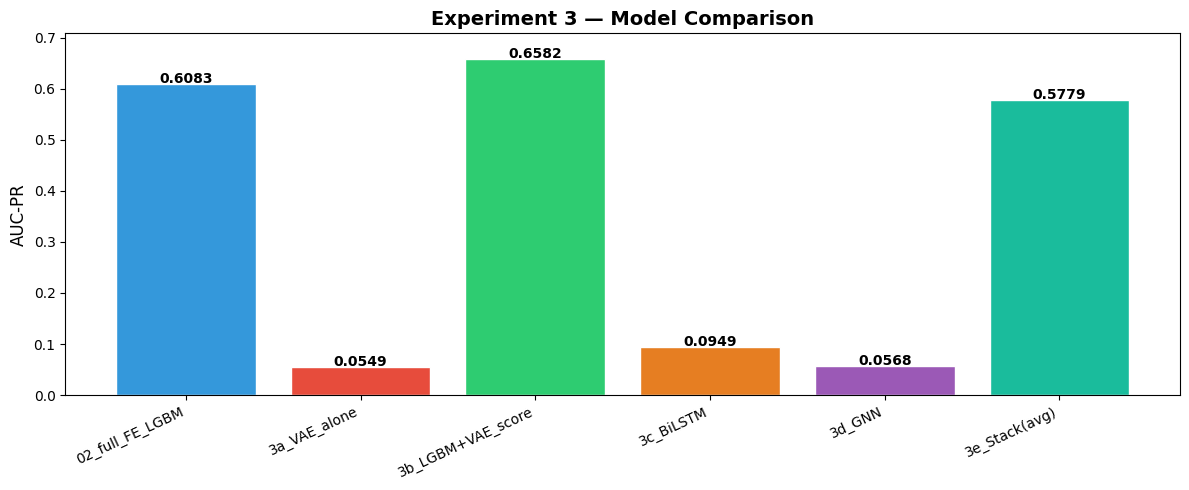

🏃 View run 3_dl_summary at: http://127.0.0.1:5000/#/experiments/3/runs/99f133da3e1445149dd8c4fa39e9bbde
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3
Run next: 04_final_tuning.ipynb


In [18]:
# ── Summary comparison chart ──────────────────────────────────────────────────
exp2_aupr = 0.0
try:
    with open('artifacts/metrics/exp02_feature_engineering.json') as f:
        exp2_aupr = json.load(f)['val_auc_pr']
except: pass

summary = {
    '02_full_FE_LGBM':     exp2_aupr,
    '3a_VAE_alone':        vae_results['val_auc_pr'],
    '3b_LGBM+VAE_score':   lgbm_aupr,
    '3c_BiLSTM':           bl_results['val_auc_pr'],
    '3d_GNN':              gnn_results['val_auc_pr'],
    '3e_Stack(avg)':       combined_aupr,
}

fig, ax = plt.subplots(figsize=(12, 5))
colors  = ['#3498db','#e74c3c','#2ecc71','#e67e22','#9b59b6','#1abc9c']
bars    = ax.bar(summary.keys(), summary.values(), color=colors, edgecolor='white')
for bar, v in zip(bars, summary.values()):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.002,
            f'{v:.4f}', ha='center', fontsize=10, fontweight='bold')
ax.set_ylabel('AUC-PR', fontsize=12)
ax.set_title('Experiment 3 — Model Comparison', fontsize=14, fontweight='bold')
ax.set_ylim(0, min(1.0, max(summary.values()) + 0.05))
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig('artifacts/shap/exp03_dl_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

# Log to MLflow
with mlflow.start_run(run_name='3_dl_summary'):
    mlflow.log_artifact('artifacts/shap/exp03_dl_comparison.png')
    mlflow.log_metrics({k.replace('(','').replace(')','').replace('+','_'): v
                        for k, v in summary.items()})

# Save JSON
with open('artifacts/metrics/exp03_deep_learning.json', 'w') as f:
    json.dump({'experiment': '03_deep_learning', 'models': summary,
               'best_aupr': combined_aupr}, f, indent=2)

print('Run next: 04_final_tuning.ipynb')